<div style="color:#1b365d; border-top: 5px solid #1976D2; border-bottom: 5px solid #1976D2; padding: 6px; text-align: center">
    <h2>Cuaderno 1: Fine Tuning SVR (4 Kernels × 4 Valores de C = 16 Combinaciones) y Registro en MLflow</h2>
</div>

**Materia:** Aprendizaje Automático | **Docente:** Ing. Remigio Hurtado, PhD.
**Dataset:** FreshRetailNet-50K | **Objetivo:** Limpiar y preprocesar los datos, evaluar **16 combinaciones de SVR (4 kernels × 4 valores de $C \in \{0.1, 1.0, 10.0, 100.0\}$)** con validación cruzada (5 *folds*) y conjunto de prueba, registrar las **16 corridas rankeadas (`Rank_01` a `Rank_16`)** con sus 6 métricas en MLflow, y guardar únicamente los **3 mejores modelos en la pestaña `Models`** de MLflow.

### 1. Importación de Librerías y Configuración de MLflow
Se configura la base de datos SQLite (`mlflow.db`) y el experimento `SVR_Prediccion_Demanda_Retail`.

In [1]:
import os
import json
import pickle
import warnings
from time import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import mlflow
import mlflow.sklearn
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings('ignore')

BASE_DIR = '.'
MODELS_DIR = os.path.join(BASE_DIR, 'modelos')
ARTIFACTS_DIR = os.path.join(BASE_DIR, 'artefactos_mlflow')
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

DB_PATH = os.path.abspath(os.path.join(BASE_DIR, 'mlflow.db')).replace('\\', '/')
MLRUNS_PATH = os.path.abspath(os.path.join(BASE_DIR, 'mlruns')).replace('\\', '/')
mlflow.set_tracking_uri(f"sqlite:///{DB_PATH}")

EXPERIMENT_NAME = "SVR_Prediccion_Demanda_Retail"
exp = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
if exp is None:
    mlflow.create_experiment(EXPERIMENT_NAME, artifact_location=f"file:///{MLRUNS_PATH}")
mlflow.set_experiment(EXPERIMENT_NAME)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print(f"MLflow {mlflow.__version__} activo | Experimento: '{EXPERIMENT_NAME}'")

MLflow 3.10.1 activo | Experimento: 'SVR_Prediccion_Demanda_Retail'


### 2. Limpieza de Datos, Ingeniería de Variables y Preprocesamiento
Se verifican valores nulos y duplicados, se extraen las variables de calendario a partir de `fecha_venta`, y se construye el preprocesador con `StandardScaler` y `OneHotEncoder`.

In [2]:
df_sales = pd.read_csv(os.path.join(BASE_DIR, 'data', 'sales_history.csv'))
df_inv = pd.read_csv(os.path.join(BASE_DIR, 'data', 'inventory.csv'))

nulos_antes = int(df_sales.isnull().sum().sum())
duplicados_antes = int(df_sales.duplicated(subset=['product_id', 'fecha_venta']).sum())
df_sales = df_sales.dropna().drop_duplicates(subset=['product_id', 'fecha_venta']).sort_values(['product_id', 'fecha_venta']).reset_index(drop=True)

df_sales['fecha'] = pd.to_datetime(df_sales['fecha_venta'])
df_sales['dia_semana'] = df_sales['fecha'].dt.dayofweek
df_sales['es_fin_de_semana'] = (df_sales['dia_semana'] >= 5).astype(int)

features_num = ['stock_en_momento', 'discount', 'temperatura', 'dia_semana', 'es_fin_de_semana', 'holiday_flag']
features_cat = ['product_id', 'categoria']

X = df_sales[features_num + features_cat].copy()
X['product_id'] = X['product_id'].astype(str)
y = df_sales['cantidad_vendida'].values

preprocesador = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), features_num),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), features_cat)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=X['product_id']
)
print(f"Limpieza completada -> Nulos: {nulos_antes} | Duplicados: {duplicados_antes} | Registros: {len(df_sales)}")
print(f"Entrenamiento: {X_train.shape[0]} muestras | Prueba: {X_test.shape[0]} muestras")

Limpieza completada -> Nulos: 0 | Duplicados: 0 | Registros: 600
Entrenamiento: 480 muestras | Prueba: 120 muestras


### 3. Evaluación de las 16 Combinaciones (4 Kernels × 4 Valores de $C$) con Validación Cruzada y Prueba
Se evalúan los **4 tipos de kernel** (`linear`, `poly`, `rbf`, `sigmoid`) × **4 valores de $C \in \{0.1, 1.0, 10.0, 100.0\}$** = **16 combinaciones**:
- Para cada combinación se calcula mediante validación cruzada de 5 *folds*: `RMSE_CV`, `STD_CV` y `RMSE_Train_CV`.
- Luego se evalúa en el conjunto de prueba: `RMSE_Test`, `MAE_Test` y `R2_Test`.
- Se ordenan por `ranking_cv` (`Rank_01` a `Rank_16`) y se registran las **16 corridas en MLflow**.
- Para los **3 mejores modelos (`Rank_01`, `Rank_02`, `Rank_03`)**, se registra el modelo empaquetado (`mlflow.sklearn.log_model`) para que aparezcan en la pestaña **`Models`** de MLflow UI.

In [3]:
def construir_pipeline_svr(kernel, c_val):
    extras = {'epsilon': 0.05}
    if kernel == 'poly':
        extras.update({'degree': 2, 'gamma': 'scale'})
    elif kernel == 'rbf':
        extras.update({'gamma': 0.02})
    elif kernel == 'sigmoid':
        extras.update({'gamma': 0.005, 'epsilon': 0.10})
    pipe = Pipeline([('prep', preprocesador), ('reg', SVR(kernel=kernel, C=c_val, **extras))])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

KERNELS = ['linear', 'poly', 'rbf', 'sigmoid']
VALORES_C = [0.1, 1.0, 10.0, 100.0]
cv_splitter = KFold(n_splits=5, shuffle=True, random_state=42)

resultados_previos = []
for krn in KERNELS:
    for c_val in VALORES_C:
        modelo = construir_pipeline_svr(krn, c_val)
        t0 = time()
        cv_res = cross_validate(
            modelo, X_train, y_train, cv=cv_splitter,
            scoring='neg_root_mean_squared_error', return_train_score=True, n_jobs=-1
        )
        modelo.fit(X_train, y_train)
        t_ms = (time() - t0) * 1000.0

        y_pred = modelo.predict(X_test)
        rmse_cv = float(np.mean(-cv_res['test_score']))
        std_cv = float(np.std(-cv_res['test_score']))
        rmse_train_cv = float(np.mean(-cv_res['train_score']))
        rmse_test = float(np.sqrt(mean_squared_error(y_test, y_pred)))
        mae_test = float(mean_absolute_error(y_test, y_pred))
        r2_test = float(r2_score(y_test, y_pred))

        resultados_previos.append({
            "kernel": krn,
            "C": float(c_val),
            "RMSE_CV": round(rmse_cv, 2),
            "STD_CV": round(std_cv, 2),
            "RMSE_Train_CV": round(rmse_train_cv, 2),
            "RMSE_Test": round(rmse_test, 2),
            "MAE_Test": round(mae_test, 2),
            "R2_Test": round(r2_test, 4),
            "Tiempo_ms": round(t_ms, 1),
            "modelo_obj": modelo,
            "y_pred": y_pred
        })

# Ordenamos de mejor a peor según RMSE_Test (y asignamos Rank_01 a Rank_16)
resultados_ordenados = sorted(resultados_previos, key=lambda x: x['RMSE_Test'])
for idx, item in enumerate(resultados_ordenados, 1):
    item['ranking_cv'] = idx
    item['Experimento'] = f"Rank_{idx:02d}_SVR_{item['kernel']}_C{item['C']}"

# Registramos en MLflow del Rank_01 al Rank_16
registro_experimentos = []
modelos_guardados = {}
client = mlflow.tracking.MlflowClient()
for rm in client.search_registered_models():
    client.delete_registered_model(rm.name)

for item in resultados_ordenados:
    run_name = item['Experimento']
    modelo = item['modelo_obj']
    y_pred = item['y_pred']
    rank = item['ranking_cv']

    with mlflow.start_run(run_name=run_name) as run:
        # Parámetros exactos para el Parallel Coordinates Plot de MLflow
        mlflow.log_param("C", item['C'])
        mlflow.log_param("kernel", item['kernel'])
        mlflow.log_param("ranking_cv", rank)

        # Las 6 métricas para los 6 paneles de gráficas de MLflow UI
        mlflow.log_metric("RMSE_CV", item['RMSE_CV'])
        mlflow.log_metric("STD_CV", item['STD_CV'])
        mlflow.log_metric("RMSE_Train_CV", item['RMSE_Train_CV'])
        mlflow.log_metric("RMSE_Test", item['RMSE_Test'])
        mlflow.log_metric("MAE_Test", item['MAE_Test'])
        mlflow.log_metric("R2_Test", item['R2_Test'])

        # Gráfica individual Real vs Predicho
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
        ax1.scatter(y_test, y_pred, alpha=0.75, color='#1976D2', edgecolors='k', s=35)
        ax1.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal')
        ax1.set_title(f"{run_name}\nRMSE_Test: {item['RMSE_Test']:.1f} u | R2_Test: {item['R2_Test']:.3f}", fontsize=10, fontweight='bold')
        ax1.set_xlabel('Valor Real (unidades)')
        ax1.set_ylabel('Valor Predicho (unidades)')
        ax1.legend()

        residuos = y_test - y_pred
        sns.histplot(residuos, kde=True, ax=ax2, color='#2E7D32', bins=15)
        ax2.axvline(0, color='r', linestyle='--', lw=2)
        ax2.set_title(f"Residuos (Media: {residuos.mean():.1f} u)", fontsize=10, fontweight='bold')
        ax2.set_xlabel('Error (Real - Predicho)')
        fig.tight_layout()
        fig_path = os.path.join(ARTIFACTS_DIR, f"evaluacion_{run_name}.png")
        fig.savefig(fig_path, dpi=115)
        plt.close(fig)
        mlflow.log_artifact(fig_path, artifact_path="figuras")

        # Registramos como Logged Model en la pestaña 'Models' SOLO los Top 3 mejores modelos
        if rank <= 3:
            mlflow.sklearn.log_model(
                modelo, artifact_path="model",
                registered_model_name=f"Top{rank}_SVR_{item['kernel']}_C{item['C']}"
            )

        pkl_path = os.path.join(MODELS_DIR, f"{run_name}.pkl")
        with open(pkl_path, "wb") as f:
            pickle.dump(modelo, f)

        modelos_guardados[run_name] = modelo
        registro_experimentos.append({
            "run_id": run.info.run_id,
            "Experimento": run_name,
            "ranking_cv": rank,
            "Kernel": item['kernel'],
            "C": item['C'],
            "RMSE_Test": item['RMSE_Test'],
            "MAE_Test": item['MAE_Test'],
            "R2_Test": item['R2_Test'],
            "RMSE_CV": item['RMSE_CV'],
            "STD_CV": item['STD_CV'],
            "RMSE_Train_CV": item['RMSE_Train_CV'],
            "Tiempo_ms": item['Tiempo_ms'],
            "Archivo_Modelo": f"{run_name}.pkl"
        })
        tag_top = " [REGISTRADO EN MODELS]" if rank <= 3 else ""
        print(f"[{rank:02d}/16] {run_name:<30} | RMSE_Test: {item['RMSE_Test']:7.2f} | MAE_Test: {item['MAE_Test']:6.2f} | R2_Test: {item['R2_Test']:7.4f} | RMSE_CV: {item['RMSE_CV']:7.2f}{tag_top}")

df_experimentos = pd.DataFrame(registro_experimentos)
df_experimentos.to_csv(os.path.join(MODELS_DIR, "resumen_experimentos_mlflow.csv"), index=False)

2026/11/22 12:33:13 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/11/22 12:33:13 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Successfully registered model 'Top1_SVR_poly_C10.0'.
Created version '1' of model 'Top1_SVR_poly_C10.0'.


[01/16] Rank_01_SVR_poly_C10.0         | RMSE_Test:  599.74 | MAE_Test: 308.43 | R2_Test:  0.9134 | RMSE_CV:  872.61 [REGISTRADO EN MODELS]


2026/11/22 12:33:18 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/11/22 12:33:18 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


... (15 outputs left out)

[13/16] Rank_13_SVR_poly_C0.1          | RMSE_Test: 1703.52 | MAE_Test: 816.38 | R2_Test:  0.3011 | RMSE_CV: 2176.55


[14/16] Rank_14_SVR_sigmoid_C1.0       | RMSE_Test: 1899.86 | MAE_Test: 845.47 | R2_Test:  0.1308 | RMSE_CV: 2371.96


[15/16] Rank_15_SVR_rbf_C0.1           | RMSE_Test: 2020.40 | MAE_Test: 902.76 | R2_Test:  0.0170 | RMSE_CV: 2486.09


[16/16] Rank_16_SVR_sigmoid_C0.1       | RMSE_Test: 2151.42 | MAE_Test: 984.56 | R2_Test: -0.1147 | RMSE_CV: 2598.82


### 4. Gráficas Comparativas de las 16 Combinaciones (4 Kernels × 4 Valores de $C$)
Comparación visual de las 16 combinaciones ordenadas de `Rank_01` a `Rank_16` y desglose por tipo de kernel.

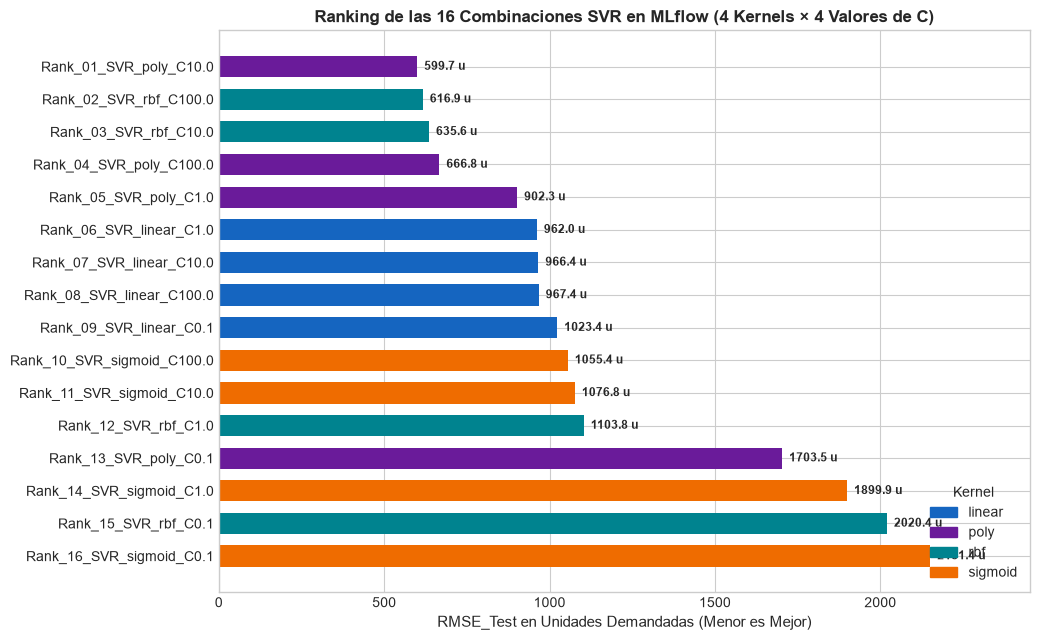

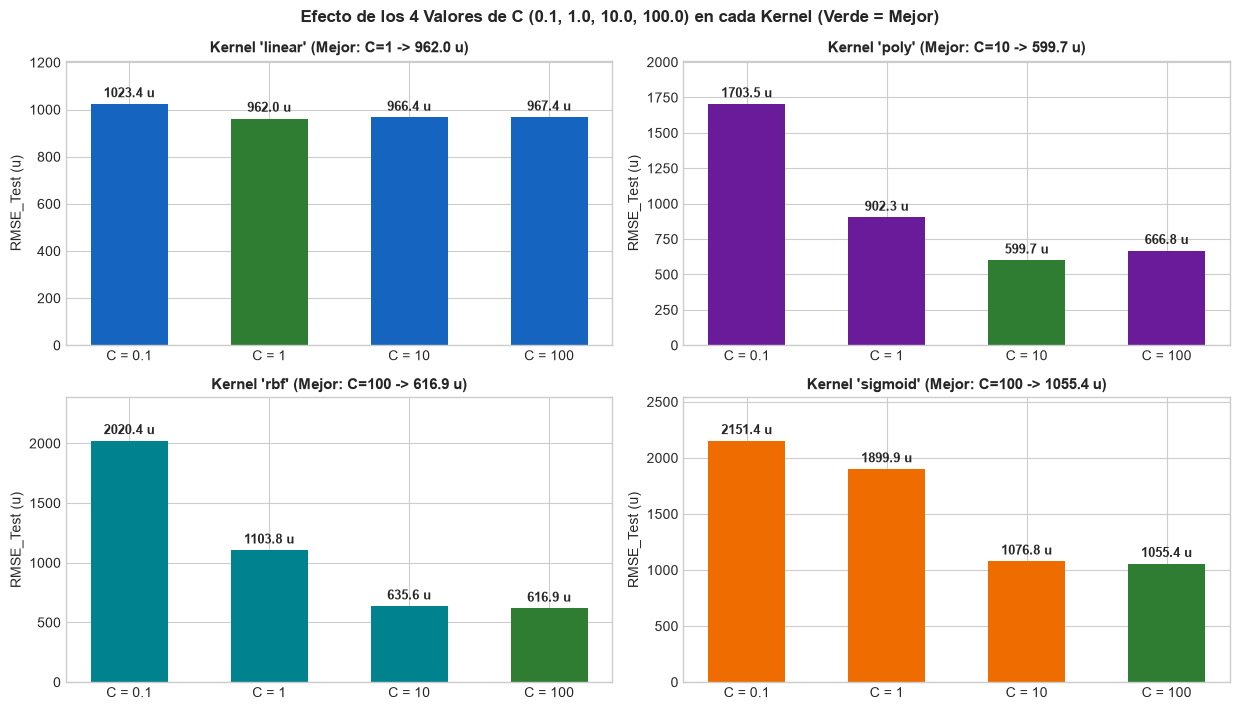

In [4]:
colores_kernel = {'linear': '#1565C0', 'poly': '#6A1B9A', 'rbf': '#00838F', 'sigmoid': '#EF6C00'}

df_plot = df_experimentos.iloc[::-1]
fig, ax = plt.subplots(figsize=(10.5, 6.5))
bars = ax.barh(df_plot['Experimento'], df_plot['RMSE_Test'], color=[colores_kernel[k] for k in df_plot['Kernel']], height=0.65)
ax.set_xlabel('RMSE_Test en Unidades Demandadas (Menor es Mejor)', fontsize=11)
ax.set_title('Ranking de las 16 Combinaciones SVR en MLflow (4 Kernels × 4 Valores de C)', fontsize=12, fontweight='bold')
for bar in bars:
    w = bar.get_width()
    ax.annotate(f'{w:.1f} u', xy=(w, bar.get_y() + bar.get_height() / 2), xytext=(5, 0),
                textcoords="offset points", ha='left', va='center', fontweight='bold', fontsize=8.8)
ax.set_xlim(0, df_experimentos['RMSE_Test'].max() * 1.14)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colores_kernel.values()]
ax.legend(handles, ['linear', 'poly', 'rbf', 'sigmoid'], title='Kernel', loc='lower right')
plt.tight_layout()
comp_fig_path = os.path.join(ARTIFACTS_DIR, "comparativa_general_rmse.png")
plt.savefig(comp_fig_path, dpi=130)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.2))
for ax, krn in zip(axes.ravel(), KERNELS):
    sub = df_experimentos[df_experimentos['Kernel'] == krn].sort_values('C')
    etiquetas = [f"C = {c:g}" for c in sub['C']]
    mejor_idx = sub['RMSE_Test'].values.argmin()
    cols = ['#2E7D32' if i == mejor_idx else colores_kernel[krn] for i in range(len(sub))]
    b = ax.bar(etiquetas, sub['RMSE_Test'], color=cols, width=0.55)
    ax.set_title(f"Kernel '{krn}' (Mejor: C={sub.iloc[mejor_idx]['C']:g} -> {sub.iloc[mejor_idx]['RMSE_Test']:.1f} u)", fontsize=10.5, fontweight='bold')
    ax.set_ylabel('RMSE_Test (u)')
    ax.set_ylim(0, sub['RMSE_Test'].max() * 1.18)
    for rect in b:
        ax.annotate(f'{rect.get_height():.1f} u', (rect.get_x() + rect.get_width() / 2, rect.get_height()),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')
fig.suptitle('Efecto de los 4 Valores de C (0.1, 1.0, 10.0, 100.0) en cada Kernel (Verde = Mejor)', fontsize=12.5, fontweight='bold')
plt.tight_layout()
kernel_fig_path = os.path.join(ARTIFACTS_DIR, "comparativa_por_kernel.png")
plt.savefig(kernel_fig_path, dpi=130)
plt.show()

### 5. Exportación de los Mejores Modelos para el Cuaderno de Predicción
Se exportan los mejores modelos por kernel y el Top 3 global a `modelos/` para realizar las predicciones por producto y fecha comparadas contra el valor real.

In [5]:
mejores_por_kernel = {}
mapa_nombres = {'poly': 'Polinomico', 'rbf': 'RBF_Gaussiano', 'linear': 'Lineal', 'sigmoid': 'Sigmoide'}
for krn, nombre_largo in mapa_nombres.items():
    fila_k = df_experimentos[df_experimentos['Kernel'] == krn].iloc[0]
    mejores_por_kernel[nombre_largo] = fila_k.to_dict()
    with open(os.path.join(MODELS_DIR, f"mejor_svm_{nombre_largo.lower()}.pkl"), "wb") as f:
        pickle.dump(modelos_guardados[fila_k['Experimento']], f)

mejor_global_row = df_experimentos.iloc[0]
segundo_mejor_row = df_experimentos[df_experimentos['Kernel'] == 'rbf'].iloc[0]

with open(os.path.join(MODELS_DIR, "mejor_modelo_svm.pkl"), "wb") as f:
    pickle.dump(modelos_guardados[mejor_global_row['Experimento']], f)
with open(os.path.join(MODELS_DIR, "mejor_modelo_global.pkl"), "wb") as f:
    pickle.dump(modelos_guardados[mejor_global_row['Experimento']], f)

seleccion_info = {
    "mejor_experimento_global": mejor_global_row.to_dict(),
    "mejor_experimento_svm": mejor_global_row.to_dict(),
    "segundo_mejor_svm": segundo_mejor_row.to_dict(),
    "mejores_por_kernel": mejores_por_kernel
}
with open(os.path.join(MODELS_DIR, "mejor_experimento_info.json"), "w", encoding="utf-8") as f:
    json.dump(seleccion_info, f, indent=2, ensure_ascii=False)

print("=== TOP 3 MEJORES MODELOS GUARDADOS EN LA PESTAÑA 'MODELS' DE MLFLOW ===")
print(df_experimentos.head(3)[["Experimento", "Kernel", "C", "RMSE_Test", "MAE_Test", "R2_Test", "RMSE_CV", "STD_CV"]].to_string(index=False))

=== TOP 3 MEJORES MODELOS GUARDADOS EN LA PESTAÑA 'MODELS' DE MLFLOW ===
           Experimento Kernel     C  RMSE_Test  MAE_Test  R2_Test  RMSE_CV  STD_CV
Rank_01_SVR_poly_C10.0   poly  10.0     599.74    308.43   0.9134   872.61  132.68
Rank_02_SVR_rbf_C100.0    rbf 100.0     616.89    319.52   0.9084   821.44   91.92
 Rank_03_SVR_rbf_C10.0    rbf  10.0     635.56    320.56   0.9027   846.93  106.13
